# Comparing the thermal models identified for VUBC

Loads the four models calibrated on the same VUBC data (season w2324, 3 h windows sliding by 1 h, 1 Dec 2023 – 1 Feb 2024, 24 h lag window, dynamic initialization) and compares their temperature forecasts on the whole heating season. All four are trained on the temperature task (`TemperatureProblem`: measured $\Phi_{HC}$ in, objective on the predicted temperatures).

| folder in `run_identification/` | model | task it was trained on |
|---|---|---|
| `six_r3c_eniso13790/VUBC` | `SixR3C_ENISO13790` | temperature: $T_i$, $T_h$ (weighted RMSE) |
| `ThreeR3C_TiThTe/VUBC` | `ThreeR3C_TiThTe` | temperature: $T_i$, $T_h$ (weighted RMSE) |
| `TwoR2C_TiTe/VUBC` | `TwoR2C_TiTe` | temperature: $T_i$ (RMSE), widened bounds |
| `ThreeR2C_TiTe/VUBC` | `ThreeR2C_TiTe` | temperature: $T_i$ (RMSE), widened bounds |

1. the calibrated runs: parameters, training error, parameters at their bounds;
2. **temperature forecast** with the measured $\Phi_{HC}$ as input: metrics, per-window error by month, forecasts over a few days.

Test windows: 24 h, sliding by 24 h, 1 Nov 2023 – 1 Apr 2024. Metrics are reported separately for the windows inside the training period (Dec–Jan) and outside it (Nov, Feb–Mar).

In [1]:
import os
from datetime import datetime, timedelta
from importlib import import_module

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rctoolbox.utils.project_root import find_project_root
from rctoolbox.pipeline.run import load_run
from rctoolbox.data.time_windows_generator import generate_time_windows
from rctoolbox.data.numpydataloader import DataLoader as NumpyDataLoader
from rctoolbox.evaluation.forecast_metrics import compute_forecast_metrics

project_root = find_project_root()
os.chdir(project_root)
RUN_DIR = project_root / "examples" / "run_identification"

## 1. Calibrated runs

In [2]:
HEMS_ID = "VUBC"

# label -> (example folder, package of the model; its build_data_dict provides init_data)
RUNS = {
    "6R3C ISO": ("six_r3c_eniso13790", "rctoolbox.models.rc.six_r3c_eniso13790"),
    "3R3C":     ("ThreeR3C_TiThTe",    "rctoolbox.models.rc.ThreeR3C_TiThTe"),
    "2R2C":     ("TwoR2C_TiTe",        "rctoolbox.models.rc.TwoR2C_TiTe"),
    "3R2C":     ("ThreeR2C_TiTe",      "rctoolbox.models.rc.ThreeR2C_TiTe"),
}
COLORS = {"6R3C ISO": "tab:orange", "3R3C": "tab:green", "2R2C": "tab:purple", "3R2C": "tab:red"}

runs = {lbl: load_run(RUN_DIR / folder / HEMS_ID / "results") for lbl, (folder, _) in RUNS.items()}
dd   = {lbl: import_module(f"{pkg}.build_data_dict") for lbl, (_, pkg) in RUNS.items()}

rows = []
for lbl, run in runs.items():
    res = run.results["results"]
    oc  = run.results["setup"]["identification_config"]["optimization_config"]
    cl  = res["clustering-results"] or {}
    rows.append({
        "model":       run.model.name,
        "model_type":  run.model_config["model_type"],
        "states":      ", ".join(run.model.states),
        "n_params":    len(run.params),
        "objective":   oc["objective_function"],
        "train_error": res["best_candidate"]["train_error"],
        "n_clusters":  len(cl),
    })
pd.DataFrame(rows, index=list(runs))

,model,model_type,states,n_params,objective,train_error,n_clusters
6R3C ISO,SixR3C_ENISO13790,6R3C_temperature,"T_i, T_h, T_m",10,__main__:weighted_temp_objective,0.17130,2
3R3C,ThreeR3C_TiThTe,3R3C_temperature,"T_i, T_h, T_e",9,objectives.py:weighted_temp_objective,0.17207,2
2R2C,TwoR2C_TiTe,2R2C_temperature,"T_i, T_e",5,RMSE,0.10876,2
3R2C,ThreeR2C_TiTe,3R2C_temperature,"T_i, T_e",8,RMSE,0.10697,1


Best parameters and their position inside the bounds used in the calibration (0 = lower, 1 = upper bound; the 2R2C and 3R2C use the widened bounds of `model_config["free_param_bounds"]` in their identification config). A parameter within 2 % of a bound is flagged: its optimum was cut by the bound.

In [3]:
for lbl, run in runs.items():
    bounds = run.parameter_space().free_param_bounds   # incl. model_config["free_param_bounds"]
    df_p = pd.DataFrame({
        "value": run.params,
        "lower": {k: bounds[k][0] for k in run.params},
        "upper": {k: bounds[k][1] for k in run.params},
    })
    df_p["position"] = (df_p["value"] - df_p["lower"]) / (df_p["upper"] - df_p["lower"])
    # at a bound: within 2 % of its value (bounds span decades, so the linear position alone misleads)
    lo, hi, v = df_p["lower"], df_p["upper"], df_p["value"]
    at_lo = np.where(lo > 0, v <= 1.02 * lo, df_p["position"] < 0.01)
    df_p["at bound"] = np.where(at_lo, "lower", np.where(v >= 0.98 * hi, "upper", ""))
    print(f"--- {lbl} ({run.model.name})")
    display(df_p.style.format({"value": "{:.4g}", "lower": "{:.4g}", "upper": "{:.4g}", "position": "{:.2f}"}))

--- 6R3C ISO (SixR3C_ENISO13790)


,value,lower,upper,position,at bound
A_f,185.1,185,354.7,0.00,lower
H_em,48.54,48.38,1795,0.00,lower
H_w,121.8,4.19,941.6,0.13,
H_ve,284.1,13.57,1182,0.23,
c_f,9.999e+06,8e+04,1e+07,1.00,upper
Phi_int,3000,0,3000,1.00,upper
A_w,27.21,2,50,0.53,
H_ih,693.3,100,1000,0.66,
C_i,1.577e+08,1e+06,1e+09,0.16,
C_h,6.837e+06,1e+05,1e+08,0.07,


--- 3R3C (ThreeR3C_TiThTe)


,value,lower,upper,position,at bound
R_ih,0.00143,0.0001,0.01,0.13,
R_ie,0.00128,0.0001,0.01,0.12,
R_ea,0.0921,0.0001,0.1,0.92,
R_ia,0.00387,0.0001,1,0.00,
C_i,1.57e+08,1e+06,1e+09,0.16,
C_h,6.771e+06,1e+05,1e+09,0.01,
C_e,8.005e+09,1e+06,1e+10,0.80,
k_sol_i,2.536,0,20,0.13,
k_sol_e,7.646,0,50,0.15,


--- 2R2C (TwoR2C_TiTe)


,value,lower,upper,position,at bound
R_ie,0.0027,8.056e-05,0.006485,0.41,
R_ea,6e-05,3e-05,0.01775,0.00,
C_i,3.273e+08,4.071e+05,1e+09,0.33,
C_e,3.277e+07,1.542e+06,1.773e+08,0.18,
k_sol,282,2.459,450,0.62,


--- 3R2C (ThreeR2C_TiTe)


,value,lower,upper,position,at bound
R_ie,0.00107,8.056e-05,0.006485,0.15,
R_ea,0.1682,0.0003005,0.18,0.93,
R_ia,0.00206,0.0006524,0.08843,0.02,
C_i,2.956e+08,4.071e+05,1e+09,0.30,
C_e,1.727e+09,1.542e+06,1.8e+09,0.96,
k_sol_e,23.22,0,144.1,0.16,
k_sol_i,5.756,0,144.1,0.04,
Phi_int,8729,462.6,1e+04,0.87,


## 2. Test data

In [4]:
DATA = pd.read_pickle(project_root / "examples" / "data" / f"{HEMS_ID}_data.pkl")
df = DATA["w2324"]["df"]

T1_TRAIN, T2_TRAIN = datetime(2023, 12, 1), datetime(2024, 2, 1)   # training period of all four runs

wdh = 24; ssh = 24
pre_window_lag = timedelta(hours=24)
tws = generate_time_windows(start_time=datetime(2023, 11, 1), end_time=datetime(2024, 4, 1),
                            samples_per_batch=int(1e6), window_duration_hours=wdh, slide_step_hours=ssh)
dataloader = NumpyDataLoader(df)
dataloader.load_all_data_batches(time_windows={"test": tws}, features=df.columns.tolist(), pre_window_lag=pre_window_lag)

batch   = dataloader.batches["test"]["batch_0"]
raw_dfs = dataloader.raw_dfs["test"]["batch_0"]
di      = batch["data_inputs"]
t       = batch["t_array"]

t_start  = pd.DatetimeIndex([row[0] for row in di["t_datetime"]])
in_train = np.asarray((t_start >= T1_TRAIN) & (t_start < T2_TRAIN))
missing  = di["missing_flag"] == 1 if "missing_flag" in di else np.zeros_like(t, dtype=bool)
print(f"{len(t_start)} test windows of {wdh} h: {in_train.sum()} inside the training period, {(~in_train).sum()} outside")

152 test windows of 24 h: 62 inside the training period, 90 outside


## 3. Temperature forecast (measured $\Phi_{HC}$ as input)

Every model gets the same inputs ($T_a$, $\Phi_{sol}$, measured $\Phi_{HC}$) and builds its initial state from the measurements with its calibrated init method (dynamic, 24 h lag). $T_h$ is a state of the 6R3C and the 3R3C only. **Persistence** (the measured value at the window start kept for 24 h) is the reference a model has to beat.

In [5]:
columns = {lbl: dd[lbl].resolve_columns() for lbl in runs}   # default mapping: T_i = y1, T_h = y2, T_a, Phi_sol, Phi_HC

pred = {}   # label -> {state name: (B, T) array}
for lbl, run in runs.items():
    c, m = columns[lbl], run.model
    y_0 = m.get_initial_state(dd[lbl].init_data(di, c))
    Y = m.forecast_temperature(y_0, t, di[c["T_a"]], di[c["Phi_sol"]], di[c["Phi_HC"]])
    pred[lbl] = {name: np.where(missing, np.nan, Y[:, :, j]) for j, name in enumerate(m.states)}

meas = {"T_i": np.where(missing, np.nan, di["y1"]), "T_h": np.where(missing, np.nan, di["y2"])}

# reference: persistence, the measured value at the window start kept over the whole window
BASELINE = "persistence"
COLORS[BASELINE] = "grey"
pred[BASELINE] = {k: np.where(missing, np.nan, np.repeat(v[:, :1], v.shape[1], axis=1)) for k, v in
                  {"T_i": di["y1"], "T_h": di["y2"]}.items()}


def metrics_table(state):
    rows = {}
    for lbl, p in pred.items():
        if state not in p:
            continue
        for part, sel in (("train period", in_train), ("outside", ~in_train), ("all", slice(None))):
            # drop t = 0: it is the measured initial value
            m_ = compute_forecast_metrics(meas[state][sel, 1:], p[state][sel, 1:])
            rows[(lbl, part)] = {k: m_[k] for k in ("RMSE", "MAE", "NMBE")}
    out = pd.DataFrame(rows).T
    out.index.names = ["model", "windows"]
    out = out.unstack("windows").reorder_levels([1, 0], axis=1)
    return out[[(part, k) for part in ("train period", "outside", "all") for k in ("RMSE", "MAE", "NMBE")]]

print("T_i [°C] (NMBE in %)")
display(metrics_table("T_i").style.format("{:.3f}"))
print("T_h [°C] (NMBE in %)")
display(metrics_table("T_h").style.format("{:.3f}"))

T_i [°C] (NMBE in %)


T_h [°C] (NMBE in %)


Distribution of the per-window RMSE of $T_i$ by month (one value per 24 h window).

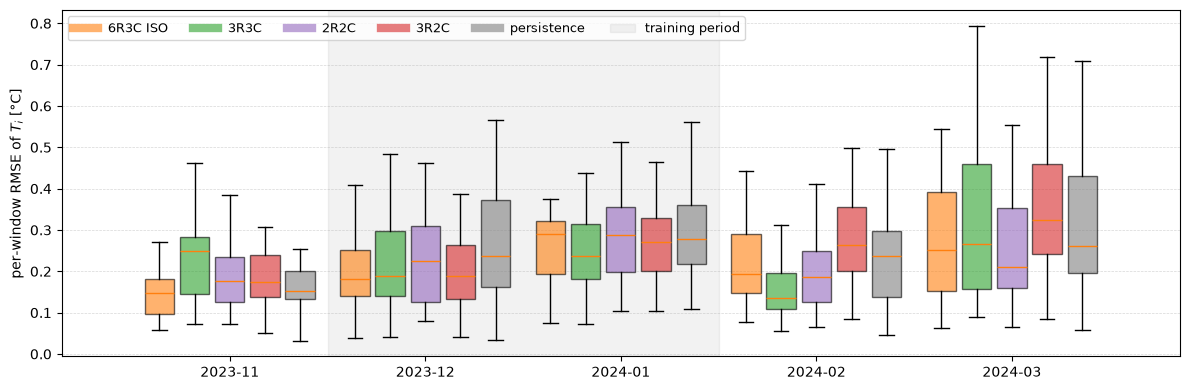

In [6]:
rmse_win = pd.DataFrame({
    lbl: np.sqrt(np.nanmean((meas["T_i"][:, 1:] - p["T_i"][:, 1:]) ** 2, axis=1)) for lbl, p in pred.items()
}, index=t_start)
months = rmse_win.index.to_period("M")

fig, ax = plt.subplots(figsize=(12, 4), dpi=100)
labels, n = list(rmse_win.columns), len(rmse_win.columns)
for k, lbl in enumerate(labels):
    groups = [rmse_win.loc[months == mo, lbl].dropna().values for mo in months.unique()]
    pos = np.arange(len(groups)) + (k - (n - 1) / 2) * 0.18
    bp = ax.boxplot(groups, positions=pos, widths=0.15, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(COLORS[lbl]); b.set_alpha(0.6)
    ax.plot([], [], color=COLORS[lbl], lw=6, alpha=0.6, label=lbl)
ax.set_xticks(np.arange(len(months.unique())))
ax.set_xticklabels([str(mo) for mo in months.unique()])
ax.axvspan(0.5, 2.5, color="grey", alpha=0.1, label="training period")
ax.set_ylabel("per-window RMSE of $T_i$ [°C]")
ax.legend(loc="upper left", ncol=6, fontsize=9)
ax.grid(axis="y", ls="--", lw=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

Forecasts over a few days outside the training period (each 24 h window starts from the measured state).

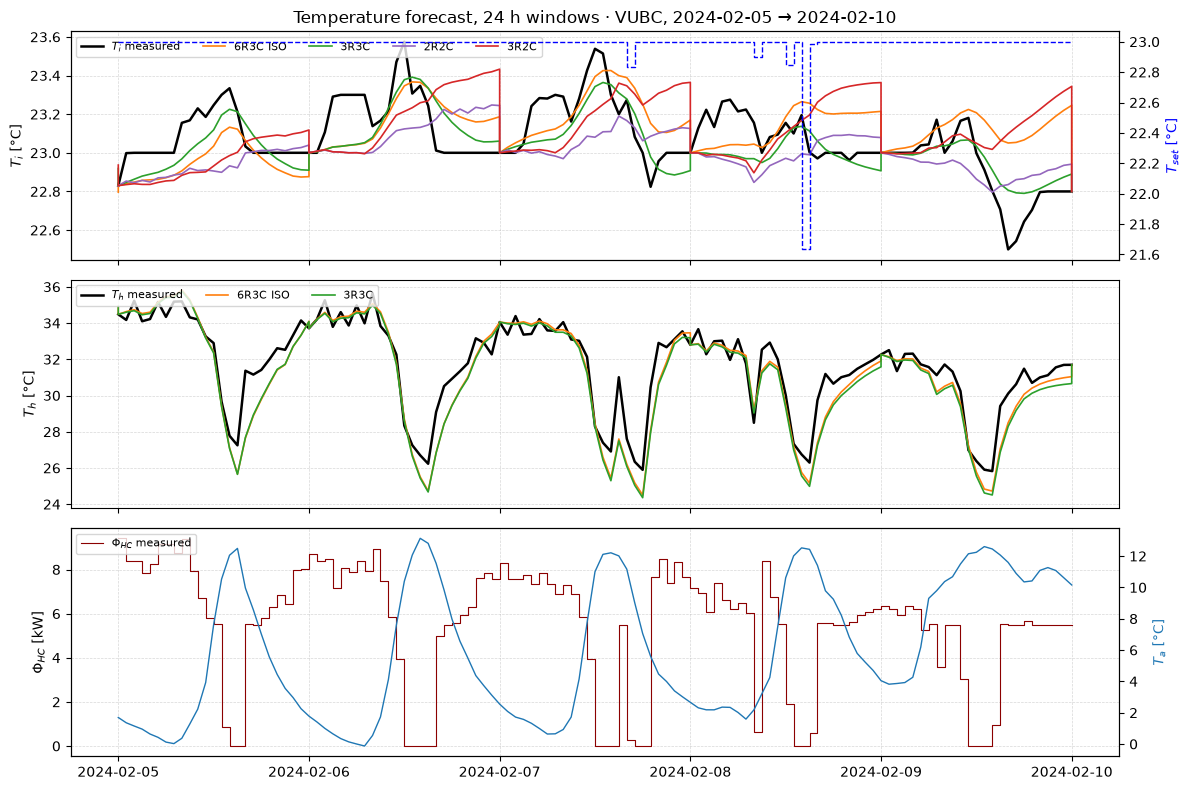

In [7]:
def to_frame(arr):
    # (B, T) -> one time series over all windows
    return pd.concat([pd.Series(arr[i], index=bdf.index) for i, bdf in enumerate(raw_dfs.values())])

t1_plot = datetime(2024, 2, 5); t2_plot = t1_plot + timedelta(days=5)
dfs = df.loc[t1_plot:t2_plot]

fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(12, 8), dpi=100, sharex=True)
ax0.plot(dfs.index, dfs["y1"], color="black", lw=1.8, label="$T_i$ measured")
ax1.plot(dfs.index, dfs["y2"], color="black", lw=1.8, label="$T_h$ measured")
for lbl, p in pred.items():
    if lbl == BASELINE:
        continue
    s = to_frame(p["T_i"]).loc[t1_plot:t2_plot]
    ax0.plot(s.index, s.values, color=COLORS[lbl], lw=1.2, label=lbl)
    if "T_h" in p:
        s = to_frame(p["T_h"]).loc[t1_plot:t2_plot]
        ax1.plot(s.index, s.values, color=COLORS[lbl], lw=1.2, label=lbl)
ax0r = ax0.twinx()
ax0r.step(dfs.index, dfs["y1_set"], where="post", color="blue", lw=1, ls="--")
ax0r.set_ylabel("$T_{set}$ [°C]", color="blue")
ax2.step(dfs.index, dfs["Phi_HC"] / 1e3, where="post", color="darkred", lw=0.8, label="$\\Phi_{HC}$ measured")
ax2r = ax2.twinx()
ax2r.plot(dfs.index, dfs["T_a"], color="tab:blue", lw=1, label="$T_a$")
ax2r.set_ylabel("$T_a$ [°C]", color="tab:blue")
ax0.set_ylabel("$T_i$ [°C]"); ax1.set_ylabel("$T_h$ [°C]"); ax2.set_ylabel("$\\Phi_{HC}$ [kW]")
for a in (ax0, ax1, ax2):
    a.legend(loc="upper left", fontsize=8, ncol=5)
    a.grid(ls="--", lw=0.5, alpha=0.5)
ax0.set_title(f"Temperature forecast, 24 h windows · VUBC, {t1_plot.date()} → {t2_plot.date()}")
plt.tight_layout()
plt.show()

## Observations (seed 23, this run)

- **$T_i$ hardly separates the models:** all four reach a season RMSE of 0.27–0.31 °C (6R3C ISO 0.27, 2R2C 0.28, 3R2C 0.30, 3R3C 0.31), but **persistence already reaches 0.32 °C**. VUBC's floor heating keeps $T_i$ within about ±0.5 °C of the setpoint, so a flat forecast is hard to beat. Outside the training period, only the 6R3C ISO (0.28) and the 2R2C (0.29) are better than persistence (0.31).
- **2R2C/3R2C and $C_i$:** after widening the bounds, their training RMSE dropped from 0.37 / 0.35 °C to 0.11 °C. They got there with a very large air capacity ($C_i \approx 3 \cdot 10^8$ J/K, about 150× the air-volume capacity): $C_i$ then acts as the slow heating floor, and the forecast $T_i$ stays nearly flat. Other compensating values: 2R2C $k_{sol}$ = 282 m², 3R2C $\Phi_{int}$ = 8.7 kW, and the 3R2C envelope almost decoupled from outdoors ($R_{ea}$ near its widened upper bound).
- **$T_h$ is where the structure matters:** 6R3C ISO and 3R3C predict it with an RMSE of 1.09 / 1.15 °C against 3.29 °C for persistence; the two-capacity models have no $T_h$ state. Both models lag the fast rise of $T_h$ after the heat pump restarts.
- **Bounds:** the 2R2C, 3R2C and 3R3C have no parameter at a bound. The 6R3C ISO (not re-calibrated) still has `A_f`, `H_em` at the lower and `c_f`, `Phi_int` at the upper bound.